# Predictive Analytics for Supply Chain Demand Forecasting and Inventory Planning

**Criselvi Lindsey · DSC 680 Project 2 · Milestone 3 (Final)**

## Project overview

This notebook evaluates whether historical daily sales can support a **16-day forecast** for the **GROCERY I** family at Favorita stores **44, 45, and 47**.

**Research questions**

1. How accurately can historical daily sales predict the next 16 days?
2. How are calendar patterns, promotional activity, and store characteristics associated with observed sales and model predictions?
3. How do random forest and histogram gradient boosting compare with a weekly seasonal naïve forecast?

The analysis follows the end-to-end data science process: data loading, inspection, preparation, feature engineering, chronological model validation, interpretation, and visual storytelling.

**Data requirement:** Download the Kaggle Store Sales – Time Series Forecasting dataset and extract train.csv and stores.csv into the notebook's working directory. Run all cells in order. The notebook generates four figures, CSV evaluation tables, and a JSON summary.

In [1]:
'''
Submitted by: Criselvi Lindsey
Class: DSC680 Applied Data Science Capstone
Project: Project 2, Milestone 3 - Supply Chain Demand Forecasting (Final)
Due Date: 11/22/2026
'''

'\nSubmitted by: Criselvi Lindsey\nClass: DSC680 Applied Data Science Capstone\nProject: Project 2, Milestone 3 - Supply Chain Demand Forecasting (Final)\nDue Date: 11/22/2026\n'

## Environment and reproducibility

Import Python libraries and configure the working directory for input and output files.

In [2]:

# Import libraries and define input/output paths

# Import the operating system library for managing file paths and directories.
import os

# Import JSON to save model results and summary information.
import json

# Import NumPy for numerical calculations and array operations.
import numpy as np

# Import pandas for loading, cleaning, and analyzing the sales data.
import pandas as pd

# Import Matplotlib for creating and displaying data visualizations.
import matplotlib.pyplot as plt

# Import the machine-learning models used for demand forecasting.
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

# Import the evaluation metric used to calculate forecast errors.
from sklearn.metrics import mean_absolute_error

# Define the input directory containing the extracted CSV files.
# The CSV files are located in the same working directory as the notebook.
DATA_DIR = '.'
# Save all generated files directly in the working directory.
ROOT = '.'
OUT = '.'

# Display the current working directory for verification.
print("Current working directory:", os.getcwd())

# Verify that the extracted sales and store files are available.
print("Sales data exists:", os.path.exists(os.path.join(DATA_DIR, 'train.csv')))
print("Store data exists:", os.path.exists(os.path.join(DATA_DIR, 'stores.csv')))

# Display the locations where the notebook will save its results.
print("Results directory:", ROOT)
print("Figures directory:", OUT)

Current working directory: C:\Users\codyl\PycharmProjects\Criselvi_School_Project\notebooks
Sales data exists: True
Store data exists: True
Results directory: .
Figures directory: .


## Load and inspect the dataset

Read the extracted train.csv and stores.csv files from the working directory. Filter the historical sales data to the GROCERY I product family and Stores 44, 45, and 47.

In [3]:
# Read the source CSV files from the current directory
d = pd.read_csv(
    'train.csv',
    usecols=['date', 'store_nbr', 'family', 'sales', 'onpromotion'],
    parse_dates=['date']
)

stores = pd.read_csv('stores.csv')

# Verify the data loaded successfully
print(f"Sales records loaded: {len(d):,}")
print(f"Store records loaded: {len(stores):,}")

display(d.head())
display(stores.head())


Sales records loaded: 3,000,888
Store records loaded: 54


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-01,1,BABY CARE,0.0,0
2,2013-01-01,1,BEAUTY,0.0,0
3,2013-01-01,1,BEVERAGES,0.0,0
4,2013-01-01,1,BOOKS,0.0,0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [4]:

# Keep the selected product family and three stores

# Filter the dataset to include only the GROCERY I product family.
# This focuses the analysis on grocery demand forecasting.
# The .copy() method creates an independent DataFrame for further analysis.
s = d[d['family'] == 'GROCERY I'].copy()

# Keep only stores 44, 45, and 47, which were selected for this project.
s = s[s['store_nbr'].isin([44, 45, 47])].copy()

# Sort the records by store number and date.
# Chronological ordering is important for time-series forecasting
# and for calculating historical sales features.
s = s.sort_values(['store_nbr', 'date']).reset_index(drop=True)

# Display the number of rows and columns in the filtered dataset.
print("Filtered dataset shape:", s.shape)

# Display the earliest and latest sales dates in the selected dataset.
print("Earliest sales date:", s['date'].min())
print("Latest sales date:", s['date'].max())

# Count the number of observations with zero recorded sales.
# Zero-sales observations may represent no sales, store closures,
# or other operational conditions that require further investigation.
zero_sales = (s['sales'] == 0).sum()
print("Number of zero-sales observations:", int(zero_sales))

# Retrieve store information for the three selected locations.
# This provides context such as city, state, store type, and cluster.
selected_stores = stores[
    stores['store_nbr'].isin([44, 45, 47])
]

# Display the store characteristics for the selected locations.
print("\nSelected store information:")
print(selected_stores.to_string(index=False))


Filtered dataset shape: (5052, 5)
Earliest sales date: 2013-01-01 00:00:00
Latest sales date: 2017-08-15 00:00:00
Number of zero-sales observations: 15

Selected store information:
 store_nbr  city     state type  cluster
        44 Quito Pichincha    A        5
        45 Quito Pichincha    A       11
        47 Quito Pichincha    A       14


**Findings.** The selected dataset contains **5,052 store-day records**, including **15 zero-sales observations**. The three selected stores are all in Quito and are type A. This makes store-type comparisons inappropriate within the selected subset.

### Join store attributes to the sales records

The sales data (`train.csv`) and store metadata (`stores.csv`) are separate sources. They are joined on the shared key `store_nbr` with a left join, so every sales record is kept. The join is validated as many-to-one: each store appears exactly once in `stores.csv`, so the join cannot duplicate sales rows.

In [5]:
# Join store metadata (city, state, type, cluster) to the selected sales records

# Record the row count before the join so the result can be verified.
rows_before = len(s)

# Left join on store_nbr keeps every sales record.
# validate='many_to_one' raises an error if any store appears more than once
# in stores.csv, which would otherwise duplicate sales rows.
s = s.merge(
    stores[['store_nbr', 'city', 'state', 'type', 'cluster']],
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

# Confirm the join did not add or drop records.
assert len(s) == rows_before, "Join changed the number of sales records."
print("Rows before join:", rows_before)
print("Rows after join:", len(s))

# Confirm every sales record received store attributes.
print("\nMissing store attributes after join:")
print(s[['city', 'state', 'type', 'cluster']].isna().sum())

# Show the attribute values for each selected store.
print("\nStore attributes in the joined data:")
print(
    s.groupby('store_nbr')[['city', 'state', 'type', 'cluster']]
    .first()
    .to_string()
)

Rows before join: 5052
Rows after join: 5052

Missing store attributes after join:
city       0
state      0
type       0
cluster    0
dtype: int64

Store attributes in the joined data:
            city      state type  cluster
store_nbr                                
44         Quito  Pichincha    A        5
45         Quito  Pichincha    A       11
47         Quito  Pichincha    A       14


**Findings and justification.** The join preserves all 5,052 records, and every record receives store attributes. All three stores share the same city (Quito), state (Pichincha), and store type (A), so these fields have no variation and cannot explain differences in sales. Cluster differs by store (5, 11, and 14) but maps one-to-one to `store_nbr`, so it adds no information beyond the store identifier. For these reasons, the models use `store_nbr` as the store feature, and store characteristics are documented here rather than used as separate predictors. This also explains why Research Question 2 cannot compare store types within this subset.

## Exploratory data analysis

Before forecasting, examine the historical sales patterns and the relationship between promotions and recorded sales. These are **descriptive associations**, not evidence that promotions caused changes in sales.

In [6]:

# Summarize sales distribution and validate data quality

# Group the filtered dataset by store number to examine
# the sales distribution for each selected store.
sales_summary = s.groupby('store_nbr')['sales'].agg([
    'count',    # Total number of daily sales observations.
    'mean',     # Average daily recorded sales.
    'median',   # Middle sales value, less sensitive to extreme observations.
    'min',      # Lowest recorded daily sales.
    'max'       # Highest recorded daily sales.
])

# Round the summary statistics to one decimal place for readability.
sales_summary = sales_summary.round(1)

# Display the sales summary for stores 44, 45, and 47.
print("Sales distribution by store:")
print(sales_summary)

# Check for missing values in the fields used for the analysis.
# Missing dates, store numbers, or sales values could affect
# the accuracy and reliability of the forecasting models.
print("\nMissing values in selected fields:")

missing_values = s[
    ['date', 'store_nbr', 'family', 'sales', 'onpromotion']
].isna().sum()

# Display the number of missing values for each selected field.
print(missing_values)

# Check for duplicate combinations of date and store number.
# Because the dataset has been filtered to one product family,
# each store should have only one sales record per date.
# Duplicate records could distort sales totals and model training.
duplicate_count = s.duplicated(
    subset=['date', 'store_nbr']
).sum()

# Display the number of duplicate store-date records.
print("\nDuplicate store/date records:", duplicate_count)


Sales distribution by store:
           count    mean  median  min      max
store_nbr                                     
44          1684  9730.4  8804.0  0.0  46271.0
45          1684  9708.9  8975.5  0.0  76090.0
47          1684  9212.9  8537.5  0.0  23024.0

Missing values in selected fields:
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate store/date records: 0


### Promotion and recorded sales

Compare average recorded sales when at least one product is on promotion versus when none is on promotion.

In [7]:
# Analyze the relationship between promotions and recorded sales

# Create a Boolean indicator identifying whether at least one
# product was on promotion during each store-day observation.
# True indicates one or more products were on promotion.
# False indicates no products were on promotion.
promotion_indicator = s['onpromotion'] > 0

# Group the sales records according to promotional activity.
# Calculate the count, mean, and median sales for each group.
promotion_summary = s.groupby(promotion_indicator)['sales'].agg([
    'count',    # Number of daily sales observations in each group.
    'mean',     # Average recorded sales for each group.
    'median'    # Middle sales value for each group.
])

# Replace the Boolean group labels with descriptive names.
# This makes the output easier to interpret in the analysis.
promotion_summary.index = promotion_summary.index.map({
    False: 'No promotion',
    True: 'At least one promotion'
})

# Round the summary statistics to one decimal place for readability.
promotion_summary = promotion_summary.round(1)

# Display the descriptive statistics for both groups.
print("Sales comparison by promotional activity:")
print(promotion_summary)


Sales comparison by promotional activity:
                        count     mean  median
onpromotion                                   
No promotion             1648   8015.1  7115.5
At least one promotion   3404  10294.2  9342.0


**Findings.** Promotional days average approximately **10,294 recorded sales units**, versus **8,015** on nonpromotional days. The data-validity check below shows that this comparison is not reliable. Future promotion counts are not assumed available for forecasting.

**Data-validity check.** This cell tests whether the promotion comparison above is affected by the period when promotion data were recorded. If promotion counts are zero for all early dates, the restricted comparison is the more reliable estimate of the promotion association. It is still descriptive, not causal.

In [8]:
# Check when promotion data begins and recompare after that date

# Identify the first date on which at least one product was on promotion.
# If promotion counts are recorded as zero before a certain date, the
# "No promotion" group would be dominated by earlier years, when sales
# were lower overall. That would confound the promotion comparison with time.
first_promo_date = s.loc[s['onpromotion'] > 0, 'date'].min()
print("First date with a recorded promotion:", first_promo_date.date())

# Count the no-promotion observations that occur before promotion
# data begins, to show how much of that group comes from the early period.
early_no_promo = (s['date'] < first_promo_date).sum()
print("Observations before promotion data begins:", early_no_promo)

# Repeat the comparison using only dates on or after the first recorded
# promotion, so both groups come from the same period.
recent = s[s['date'] >= first_promo_date]

recent_promotion_summary = recent.groupby(
    recent['onpromotion'] > 0
)['sales'].agg(['count', 'mean', 'median']).round(1)

# Replace the Boolean group labels with descriptive names.
recent_promotion_summary.index = recent_promotion_summary.index.map({
    False: 'No promotion',
    True: 'At least one promotion'
})

print("\nSales comparison by promotional activity (after promotion data begins):")
print(recent_promotion_summary)


First date with a recorded promotion: 2014-06-25
Observations before promotion data begins: 1617

Sales comparison by promotional activity (after promotion data begins):
                        count     mean  median
onpromotion                                   
No promotion               31   6492.8  6592.0
At least one promotion   3404  10294.2  9342.0


**Findings.** Promotion counts begin on **June 25, 2014**. Of the 1,648 no-promotion store-days, **1,617 occur before that date**, and only **31** no-promotion days remain afterward. The raw comparison therefore mainly contrasts earlier, lower-sales years with later years. Promotional effects cannot be estimated reliably in this subset, which supports excluding promotions from the forecasting models.

## Feature engineering and data preparation

The objective is to construct **origin-safe** features. For a forecast issued on a given day, lagged and rolling sales features must use only sales recorded up to that day. The target is each of the next 16 days. This prevents future-information leakage.

In [9]:

# Generate historical lag and rolling-average features at each prediction origin

# Create an empty list to store the forecasting observations.
# Each observation represents one store, forecast origin, and forecast horizon.
rows = []

# Process each selected store independently to ensure that historical
# sales information from different stores is not combined.
for st, g in s.groupby('store_nbr'):

    # Set the date as the index and sort records chronologically.
    # This ensures that historical sales features follow the correct time order.
    g = g.set_index('date').sort_index()

    # Extract the sales series and corresponding dates for the current store.
    y = g['sales']
    dates = g.index

    # Generate forecast origins at intervals of 16 observations.
    # Start at index 35 to ensure sufficient historical sales data.
    # Reserve the following 16 observations for forecast evaluation.
    for oi in range(35, len(g) - 16, 16):

        # Identify the date on which the forecast is generated.
        origin = dates[oi]

        # Use only sales observations available through the forecast origin.
        # This prevents future sales information from entering the predictors.
        hist = y.iloc[:oi + 1]

        # Generate predictions for each of the next 16 days.
        for h in range(1, 17):

            # Identify the target observation and its corresponding date.
            ti = oi + h
            target = dates[ti]

            # Confirm that the target date is exactly h calendar days
            # after the forecast origin.
            # Skip records if missing dates would misalign the forecast horizon.
            if (target - origin).days != h:
                continue

            # Retrieve the most recently observed daily sales value.
            # This is the lag-1 feature relative to the forecast origin.
            last = float(hist.iloc[-1])

            # Retrieve the seventh-to-last observed sales value.
            # This is the oldest observation in the trailing seven-day window.
            prior7 = float(hist.iloc[-7])

            # Calculate average sales over the most recent seven observations.
            # This captures short-term sales behavior.
            mean7 = float(hist.iloc[-7:].mean())

            # Calculate average sales over the most recent 28 observations.
            # This captures a broader four-week sales pattern.
            mean28 = float(hist.iloc[-28:].mean())

            # Create the seasonal naïve forecasting benchmark.
            # Repeat the last seven observed sales values.
            # For horizons 8–16, cycle through the same weekly pattern.
            baseline = float(
                hist.iloc[-7 + ((h - 1) % 7)]
            )

            # Store the forecast target, historical features,
            # seasonal benchmark, and calendar information.
            rows.append({
                'store_nbr': st,
                'origin': origin,
                'target_date': target,
                'horizon': h,

                # Actual future sales used only for model evaluation.
                'y': float(y.iloc[ti]),

                # Seasonal naïve forecast for baseline comparison.
                'seasonal': baseline,

                # Historical sales features available at the origin.
                'lag1': last,
                'lag7': prior7,
                'avg7': mean7,
                'avg28': mean28,

                # Calendar features for the future target date.
                'dayofweek': target.dayofweek,
                'month': target.month,
                'day': target.day,
                'dayofyear': target.dayofyear,
                'dayofmonth': target.day,

                # Store identifier used during model training.
                'store': st
            })

# ------------------------------------------------------------
# Convert generated observations into a forecasting DataFrame
# ------------------------------------------------------------

# Convert the list of dictionaries into a pandas DataFrame.
# Use the variable name 'f' to remain consistent with subsequent model code.
f = pd.DataFrame(rows)

# Display the total number of forecasting observations generated.
print("Total forecasting observations:", f"{len(f):,}")

# Display the number of observations generated for each store.
print("\nForecasting observations by store:")
print(f.groupby('store_nbr').size())

# Display the earliest and latest forecast origins.
print("\nForecast origin date range:")
print("Earliest origin:", f['origin'].min())
print("Latest origin:", f['origin'].max())

# Display the forecast horizons included in the dataset.
print("\nForecast horizons:")
print("Minimum horizon:", f['horizon'].min())
print("Maximum horizon:", f['horizon'].max())

# ------------------------------------------------------------
# Display sample forecasting observations
# ------------------------------------------------------------

# Display the first 10 observations to verify the calculated
# lag features, rolling averages, seasonal forecasts, and target dates.
print("\nSample forecasting features:")
display(f.head(10))

# ------------------------------------------------------------
# Validate the generated forecasting dataset
# ------------------------------------------------------------

# Check for missing values in the generated features.
# Missing predictor values may prevent successful model training.
print("\nMissing values in forecasting features:")
print(f.isna().sum())

# Check for duplicate store, origin, and horizon combinations.
# Each combination should identify one unique forecast observation.
duplicate_count = f.duplicated(
    subset=['store_nbr', 'origin', 'horizon']
).sum()

print("\nDuplicate forecasting observations:", duplicate_count)

# Confirm that each target date matches its forecast horizon.
# This verifies that the forecast periods are correctly aligned.
date_alignment = (
    (f['target_date'] - f['origin']).dt.days
    == f['horizon']
)

print("All forecast dates correctly aligned:", date_alignment.all())

# Display a confirmation message after feature generation.
print("\nHistorical feature engineering completed successfully.")

Total forecasting observations: 4,851

Forecasting observations by store:
store_nbr
44    1617
45    1617
47    1617
dtype: int64

Forecast origin date range:
Earliest origin: 2013-02-05 00:00:00
Latest origin: 2017-07-30 00:00:00

Forecast horizons:
Minimum horizon: 1
Maximum horizon: 16

Sample forecasting features:


,store_nbr,origin,target_date,horizon,y,seasonal,lag1,lag7,avg7,avg28,dayofweek,month,day,dayofyear,dayofmonth,store
0,44,2013-02-05,2013-02-06,1,7160.0,5669.0,5903.0,5669.0,7357.142857,7436.25,2,2,6,37,6,44
1,44,2013-02-05,2013-02-07,2,5444.0,4268.0,5903.0,5669.0,7357.142857,7436.25,3,2,7,38,7,44
2,44,2013-02-05,2013-02-08,3,5826.0,7265.0,5903.0,5669.0,7357.142857,7436.25,4,2,8,39,8,44
3,44,2013-02-05,2013-02-09,4,7683.0,11068.0,5903.0,5669.0,7357.142857,7436.25,5,2,9,40,9,44
4,44,2013-02-05,2013-02-10,5,5655.0,11125.0,5903.0,5669.0,7357.142857,7436.25,6,2,10,41,10,44
5,44,2013-02-05,2013-02-11,6,5790.0,6202.0,5903.0,5669.0,7357.142857,7436.25,0,2,11,42,11,44
6,44,2013-02-05,2013-02-12,7,7601.0,5903.0,5903.0,5669.0,7357.142857,7436.25,1,2,12,43,12,44
7,44,2013-02-05,2013-02-13,8,6542.0,5669.0,5903.0,5669.0,7357.142857,7436.25,2,2,13,44,13,44
8,44,2013-02-05,2013-02-14,9,26067.0,4268.0,5903.0,5669.0,7357.142857,7436.25,3,2,14,45,14,44
9,44,2013-02-05,2013-02-15,10,6214.0,7265.0,5903.0,5669.0,7357.142857,7436.25,4,2,15,46,15,44



Missing values in forecasting features:
store_nbr      0
origin         0
target_date    0
horizon        0
y              0
seasonal       0
lag1           0
lag7           0
avg7           0
avg28          0
dayofweek      0
month          0
day            0
dayofyear      0
dayofmonth     0
store          0
dtype: int64

Duplicate forecasting observations: 0
All forecast dates correctly aligned: True

Historical feature engineering completed successfully.


In [10]:

# Include the three validation origins and the final 16-day holdout

# ------------------------------------------------------------
# Step 1: Define the chronological evaluation origins
# ------------------------------------------------------------

# Specify three validation origins and one final holdout origin.
# Each origin represents the date on which a 16-day forecast
# is generated using historical sales available up to that date.
#
# Validation 1: June 12, 2017
# Validation 2: June 28, 2017
# Validation 3: July 14, 2017
# Final holdout: July 30, 2017
evaluation_origins = pd.to_datetime([
    '2017-06-12',
    '2017-06-28',
    '2017-07-14',
    '2017-07-30'
])


# ------------------------------------------------------------
# Step 2: Process each selected store independently
# ------------------------------------------------------------

# Group the historical GROCERY I sales observations by store.
# The selected stores are 44, 45, and 47.
for st, g in s.groupby('store_nbr'):

    # Set the date as the index and sort observations
    # chronologically to preserve the time-series order.
    g = g.set_index('date').sort_index()

    # Store the historical sales values and available dates.
    y = g['sales']
    dates = g.index

    # --------------------------------------------------------
    # Step 3: Process each validation and holdout origin
    # --------------------------------------------------------

    # Loop through the four predefined evaluation origins.
    for origin in evaluation_origins:

        # Skip the origin if the store has no observation
        # recorded on that date.
        if origin not in g.index:
            continue

        # Identify the position of the current forecast origin
        # within the store's chronological observations.
        oi = g.index.get_loc(origin)

        # Select historical sales up to and including
        # the forecast origin.
        # Future sales observations are excluded from
        # the historical predictor calculations.
        hist = y.iloc[:oi + 1]

        # ----------------------------------------------------
        # Step 4: Generate the 16-day forecast observations
        # ----------------------------------------------------

        # Generate one forecast observation for each horizon,
        # from one day ahead through sixteen days ahead.
        for h in range(1, 17):

            # Calculate the future target date corresponding
            # to the current forecast horizon.
            target = origin + pd.Timedelta(days=h)

            # Skip target dates that are not available
            # in the store's historical sales dataset.
            if target not in g.index:
                continue

            # ------------------------------------------------
            # Step 5: Create the forecasting feature record
            # ------------------------------------------------

            # Append the actual sales, seasonal baseline,
            # historical sales features, and calendar features.
            #
            # The seasonal baseline repeats the seven most
            # recently observed sales values across the
            # 16-day forecast horizon.
            #
            # Historical lag and average features are calculated
            # using observations available at the forecast origin.
            #
            # Calendar features describe the future target date
            # and are known in advance.
            rows.append(
                dict(
                    # Store and forecast identification.
                    store_nbr=st,
                    origin=origin,
                    target_date=target,
                    horizon=h,

                    # Actual sales recorded on the target date.
                    # Used as the evaluation target, not a predictor.
                    y=float(g.loc[target, 'sales']),

                    # Seasonal naïve forecast based on the
                    # repeating seven-observation sales pattern.
                    seasonal=float(
                        hist.iloc[-7 + ((h - 1) % 7)]
                    ),

                    # Most recently observed sales at the origin.
                    lag1=float(hist.iloc[-1]),

                    # Seventh-to-last observed sales value.
                    lag7=float(hist.iloc[-7]),

                    # Mean of the last seven observed sales values.
                    avg7=float(hist.iloc[-7:].mean()),

                    # Mean of the last 28 observed sales values.
                    avg28=float(hist.iloc[-28:].mean()),

                    # Calendar features for the target date.
                    dayofweek=target.dayofweek,
                    month=target.month,
                    day=target.day,
                    dayofyear=target.dayofyear,
                    dayofmonth=target.day,

                    # Store identifier used as a model predictor.
                    store=st
                )
            )


# ------------------------------------------------------------
# Step 6: Create the final forecasting feature dataset
# ------------------------------------------------------------

# Convert the collected forecasting records into a DataFrame.
f = pd.DataFrame(rows)

# Remove duplicate combinations of store, forecast origin,
# and forecast horizon.
#
# Some evaluation origins may already have been generated
# during the earlier historical feature-engineering step.
# Removing duplicates prevents repeated evaluation records.
f = f.drop_duplicates(
    ['store_nbr', 'origin', 'horizon']
)

# Sort the observations chronologically by forecast origin,
# then by store number and forecast horizon.
f = f.sort_values(
    ['origin', 'store_nbr', 'horizon']
)


# ------------------------------------------------------------
# Step 7: Display the prepared forecasting dataset
# ------------------------------------------------------------

# Display the total number of forecasting observations.
print("Prepared forecasting rows:", len(f))

# Display the first five forecasting records.
# These columns show the forecast origin, target date,
# store number, horizon, actual sales, and seasonal forecast.
print(
    f[
        [
            'origin',
            'target_date',
            'store_nbr',
            'horizon',
            'y',
            'seasonal'
        ]
    ].head().to_string(index=False)
)


Prepared forecasting rows: 4851
    origin target_date  store_nbr  horizon      y  seasonal
2013-02-05  2013-02-06         44        1 7160.0    5669.0
2013-02-05  2013-02-07         44        2 5444.0    4268.0
2013-02-05  2013-02-08         44        3 5826.0    7265.0
2013-02-05  2013-02-09         44        4 7683.0   11068.0
2013-02-05  2013-02-10         44        5 5655.0   11125.0


**Findings.** Each forecast row has a store, forecast origin, future target date, horizon, and recorded sales target. The seasonal naïve baseline repeats the most recent observed weekly pattern. All model inputs are known at the forecast origin or are calendar attributes of the target date.

## Modeling methods and evaluation criteria

### Why these three methods

| Method | Role | Why it fits this problem and dataset |
|---|---|---|
| **Seasonal naïve** (repeat the last 7 observed days) | Operational benchmark | Grocery sales follow a strong weekly cycle (see Figure 2), so "next week looks like last week" is a realistic rule a planner might already use. Any model worth deploying must beat it. |
| **Random forest regression** | Candidate model | Averages many decision trees trained on bootstrap samples. It captures nonlinear effects and interactions (for example, weekday × store × recent level) without manual specification, and averaging makes it robust to noisy days and outliers. |
| **Histogram-based gradient boosting** | Candidate model | Builds trees sequentially, each correcting the previous errors. Binning features into histograms makes it fast, and tree-based gradient boosting performed strongly in the M5 retail forecasting competition (Makridakis et al., 2022). Learning rate, leaf limits, and L2 regularization control overfitting on a small dataset. |

Both tree models predict `log1p(sales)` rather than raw sales. Daily sales are right-skewed with occasional extreme spikes, so the log scale stabilizes variance and keeps a few very large days from dominating training. Predictions are converted back with `expm1` and clipped at zero.

### Alternatives considered and not used

- **ARIMA or exponential smoothing per store:** strong classical methods (Hyndman & Athanasopoulos, 2021), but each store would need separate tuning, and they incorporate calendar features and cross-store information less flexibly than one pooled tree model.
- **Linear regression:** transparent, but it assumes additive, linear effects and would need many hand-built interaction terms to represent the weekday-by-level patterns the trees learn automatically.
- **Deep learning (LSTM networks):** designed for long sequences and large datasets. Three series and about 2,700 training examples per window do not justify the added complexity, tuning cost, or loss of interpretability.

### Validation design: rolling-origin time-series cross-validation

Standard k-fold cross-validation shuffles observations, which would let a model train on future days and test on past ones. That leaks information and overstates accuracy for forecasting. This project instead uses **rolling-origin (time-series) cross-validation**: for each of three consecutive 16-day windows, the models are retrained using only forecast examples whose origins and target dates fall before the window begins, then scored on that window. A fourth, untouched 16-day period (July 31 to August 15, 2017) serves as the final holdout. Every method is scored on the identical 48 store-day observations in each window.

### Evaluation metrics

- **MAE** (mean absolute error): average miss in recorded sales units, the most interpretable measure for a planner.
- **WAPE** (weighted absolute percentage error): total error as a share of total sales, comparable across stores and periods.
- **RMSLE** (root mean squared logarithmic error): the competition metric, which measures relative error and is less sensitive to a few very large days.

Model settings are fixed in advance rather than tuned on the holdout, so the holdout remains an honest test.

In [11]:

# Define predictors and chronological validation windows

# Specify the predictor variables used by both machine-learning models.
# These features were generated during historical feature engineering.
features = [

    # Number of days ahead being forecast (1 through 16).
    'horizon',

    # Historical sales features available at the forecast origin.
    'lag1',        # Most recently observed daily sales.
    'lag7',        # Seventh-to-last observed sales.
    'avg7',        # Average sales over the last 7 observations.
    'avg28',       # Average sales over the last 28 observations.

    # Calendar features known for each future forecast date.
    'dayofweek',   # Day of the week (Monday=0, Sunday=6).
    'month',       # Calendar month (1 through 12).
    'dayofyear',   # Day of the year (1 through 366).

    # Store identifier distinguishes the three selected locations.
    'store'
]

# Promotional activity is intentionally excluded from the predictors.
# Future promotion schedules were not verified as available at the
# forecast origin. Using actual future promotions could cause data leakage.

# Define four chronological forecast origins for model evaluation.
# The first three periods are used for rolling-origin validation.
# The final period is reserved for the holdout evaluation.
origins = pd.to_datetime([
    '2017-06-12',  # Validation 1: June 13–28, 2017.
    '2017-06-28',  # Validation 2: June 29–July 14, 2017.
    '2017-07-14',  # Validation 3: July 15–30, 2017.
    '2017-07-30'   # Final holdout: July 31–August 15, 2017.
])

# ------------------------------------------------------------
# Display the predictor variables
# ------------------------------------------------------------

# Print the number of predictors used in model training.
print("Total model predictors:", len(features))

# Display each predictor to document the model configuration.
print("\nModel predictor variables:")

for feature in features:
    print(f"  - {feature}")

# ------------------------------------------------------------
# Display the chronological evaluation windows
# ------------------------------------------------------------

print("\nChronological validation and holdout periods:")

# Loop through each forecast origin and calculate its 16-day period.
for i, origin in enumerate(origins):

    # The evaluation period begins one day after the forecast origin.
    start_date = origin + pd.Timedelta(days=1)

    # Each evaluation period covers the next 16 calendar days.
    end_date = origin + pd.Timedelta(days=16)

    # Identify the first three periods as validation windows.
    # The fourth period is the final holdout.
    period_type = (
        "Final holdout"
        if i == len(origins) - 1
        else f"Validation {i + 1}"
    )

    # Display the evaluation period and its corresponding dates.
    print(
        f"{period_type}: "
        f"{start_date.date()} through {end_date.date()}"
    )

# Confirm that the predictors and evaluation periods are defined.
print("\nPredictors and evaluation windows configured successfully.")


Total model predictors: 9

Model predictor variables:
  - horizon
  - lag1
  - lag7
  - avg7
  - avg28
  - dayofweek
  - month
  - dayofyear
  - store

Chronological validation and holdout periods:
Validation 1: 2017-06-13 through 2017-06-28
Validation 2: 2017-06-29 through 2017-07-14
Validation 3: 2017-07-15 through 2017-07-30
Final holdout: 2017-07-31 through 2017-08-15

Predictors and evaluation windows configured successfully.


In [12]:

# Configure and train both machine-learning methods

# Define a reusable function that trains the forecasting models.
# The function receives a training DataFrame and returns fitted models.
def fit_models(train):

    # Select the predictor variables defined in the features list.
    # Both models use the same predictors for a fair comparison.
    X = train[features]

    # Apply a log(1 + y) transformation to the recorded sales values.
    # This reduces the influence of larger sales values during training.
    # Predictions will later be converted to the original sales scale.
    yy = np.log1p(train['y'])

    # Initialize the two machine-learning regression models.
    # Both use random_state=42 to support reproducibility.
    models = {

        # Random Forest combines predictions from multiple decision trees.
        # n_estimators=90 specifies the number of trees.
        # max_depth=12 limits the depth of each tree.
        # min_samples_leaf=3 requires at least 3 samples per leaf.
        # n_jobs=-1 uses available CPU cores for parallel processing.
        'Random forest': RandomForestRegressor(
            n_estimators=90,
            max_depth=12,
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=42
        ),

        # Histogram Gradient Boosting builds trees sequentially.
        # Each iteration attempts to improve the existing predictions.
        # max_iter=150 specifies the number of boosting iterations.
        # max_leaf_nodes=15 limits the complexity of each tree.
        # l2_regularization=3 helps reduce overfitting.
        # learning_rate=0.07 controls the size of each update.
        'Histogram gradient boosting': HistGradientBoostingRegressor(
            max_iter=150,
            max_leaf_nodes=15,
            l2_regularization=3,
            learning_rate=0.07,
            random_state=42
        )
    }

    # Train each model using the historical predictor variables
    # and log-transformed sales values.
    for model in models.values():
        model.fit(X, yy)

    # Return the fitted models for prediction and evaluation.
    return models


# ------------------------------------------------------------
# Display model configuration information
# ------------------------------------------------------------

# Confirm that the model-training function has been defined.
print("Model-training function defined successfully.")

# Display the forecasting methods configured for this project.
print("\nConfigured machine-learning models:")
print("1. Random Forest Regressor")
print("2. Histogram Gradient Boosting Regressor")

# Display the predictor count used by both models.
print("\nNumber of predictor variables:", len(features))

# Explain when model training will occur.
print("\nModel training will occur during chronological validation.")

# Confirm that the function is ready for use.
print("\nModel configuration completed successfully.")


Model-training function defined successfully.

Configured machine-learning models:
1. Random Forest Regressor
2. Histogram Gradient Boosting Regressor

Number of predictor variables: 9

Model training will occur during chronological validation.

Model configuration completed successfully.


In [13]:

# Evaluate RMSLE, MAE, and WAPE on the same forecast observations

# Define a reusable function to calculate three forecasting
# performance metrics using actual and predicted sales values.
def metric(y, p):

    # Convert negative predictions to zero.
    # Recorded sales cannot be negative, so negative forecast
    # values are adjusted before calculating evaluation metrics.
    p = np.maximum(0, p)

    # Calculate Root Mean Squared Logarithmic Error (RMSLE).
    # The log1p transformation calculates log(1 + value),
    # allowing zero sales values to be included.
    # Squared logarithmic differences are averaged, then
    # the square root is taken to obtain RMSLE.
    rmsle = float(
        np.sqrt(
            np.mean(
                (np.log1p(y) - np.log1p(p)) ** 2
            )
        )
    )

    # Calculate Mean Absolute Error (MAE).
    # MAE measures the average absolute difference between
    # actual and predicted sales in recorded sales units.
    # Lower MAE indicates better forecasting accuracy.
    mae = float(
        np.mean(
            np.abs(y - p)
        )
    )

    # Calculate Weighted Absolute Percentage Error (WAPE).
    # WAPE divides the total absolute forecasting error
    # by the total actual recorded sales.
    # The result is expressed as a decimal (e.g., 0.15 = 15%).
    # Lower WAPE indicates better forecasting accuracy.
    wape = float(
        np.sum(np.abs(y - p)) / np.sum(y)
    )

    # Return all three evaluation metrics in a dictionary.
    # These results will be used to compare forecasting models.
    return {
        'RMSLE': rmsle,
        'MAE': mae,
        'WAPE': wape
    }


# ------------------------------------------------------------
# Display metric configuration information
# ------------------------------------------------------------

# Confirm that the evaluation function has been defined.
print("Forecast evaluation function defined successfully.")

# Display the performance metrics used in the analysis.
print("\nConfigured evaluation metrics:")
print("1. RMSLE - Root Mean Squared Logarithmic Error")
print("2. MAE   - Mean Absolute Error")
print("3. WAPE  - Weighted Absolute Percentage Error")

# Explain how to interpret the evaluation metrics.
print("\nInterpretation: Lower values indicate better forecasting accuracy.")

# Confirm that the function is ready for model evaluation.
print("\nEvaluation metrics configured successfully.")


Forecast evaluation function defined successfully.

Configured evaluation metrics:
1. RMSLE - Root Mean Squared Logarithmic Error
2. MAE   - Mean Absolute Error
3. WAPE  - Weighted Absolute Percentage Error

Interpretation: Lower values indicate better forecasting accuracy.

Evaluation metrics configured successfully.


## Rolling-origin time-series cross-validation and final holdout

Fit each model using only earlier forecast examples, then evaluate the three methods on identical future observations. The three validation periods precede the final holdout of **July 31–August 15, 2017**.

In [14]:

# Run chronological backtests and collect model predictions

# Initialize an empty list to store evaluation metrics.
# Each record will contain the forecast origin, model name,
# RMSLE, MAE, and WAPE.
results = []

# Initialize an empty list to store individual predictions.
# These predictions will be used later for model comparisons,
# visualizations, and the final holdout analysis.
predictions = []

# ------------------------------------------------------------
# Step 1: Loop through the chronological forecast origins
# ------------------------------------------------------------

# Evaluate the three validation windows and the final holdout.
# Each origin represents the date when a forecast is generated.
for origin in origins:

    # Select historical observations for model training.
    # The target date must occur strictly before the forecast origin.
    # The historical forecast origin must also precede the current
    # evaluation origin.
    # Only training examples with origins on or after
    # January 1, 2015, are included.
    #
    # These conditions prevent future target values from entering
    # the training data for the current evaluation period.
    train = f[
        (f['target_date'] < origin) &
        (f['origin'] < origin) &
        (f['origin'] >= pd.Timestamp('2015-01-01'))
    ]

    # Select the observations associated with the current
    # forecast origin.
    # The test set contains the future dates to be predicted
    # for each selected store.
    test = f[f['origin'] == origin].copy()

    # Display the forecast origin and the number of observations
    # used for training and testing.
    print(
        "Origin:", origin.date(),
        "| Training observations:", len(train),
        "| Test observations:", len(test)
    )

    # --------------------------------------------------------
    # Step 2: Train the machine-learning models
    # --------------------------------------------------------

    # Call the previously defined fit_models() function.
    # Both models are fitted using the same historical
    # training observations and predictor variables.
    models = fit_models(train)

    # --------------------------------------------------------
    # Step 3: Generate predictions for all three methods
    # --------------------------------------------------------

    # Compare the seasonal naïve baseline with Random Forest
    # and Histogram Gradient Boosting.
    for name in [
        'Seasonal naïve',
        'Random forest',
        'Histogram gradient boosting'
    ]:

        # Seasonal naïve uses the historical seasonal
        # reference value already calculated in the dataset.
        # It does not require machine-learning model training.
        if name == 'Seasonal naïve':

            pred = test['seasonal'].to_numpy()

        else:

            # Generate predictions using the fitted model.
            # The model predicts log-transformed sales values.
            log_predictions = models[name].predict(
                test[features]
            )

            # Convert the predictions back to the original
            # sales scale using the inverse log1p transformation.
            pred = np.expm1(log_predictions)

        # Replace any negative predictions with zero.
        # Sales forecasts cannot represent negative sales units.
        pred = np.maximum(0, pred)

        # ----------------------------------------------------
        # Step 4: Calculate forecasting performance metrics
        # ----------------------------------------------------

        # Compare actual sales with predicted sales using
        # the previously defined metric() function.
        # All three models are evaluated on the same test rows.
        sc = metric(
            test['y'].to_numpy(),
            pred
        )

        # Store the forecast origin, model name, and
        # calculated evaluation metrics.
        results.append(
            dict(
                origin=str(origin.date()),
                model=name,
                **sc
            )
        )

        # ----------------------------------------------------
        # Step 5: Collect individual forecast predictions
        # ----------------------------------------------------

        # Retain the identifying information and actual sales
        # for each store, target date, and forecast horizon.
        temp = test[
            [
                'origin',
                'target_date',
                'store_nbr',
                'horizon',
                'y'
            ]
        ].copy()

        # Add the forecasting method used for each prediction.
        temp['model'] = name

        # Add the predicted sales values.
        temp['prediction'] = pred

        # Append the predictions to the collection.
        predictions.append(temp)

    # Display a separator between evaluation periods.
    print("-" * 65)


# ------------------------------------------------------------
# Step 6: Display a summary of the completed backtests
# ------------------------------------------------------------

# Convert the collected evaluation results to a DataFrame
# for easier review without changing the original results list.
results_preview = pd.DataFrame(results)

# Display the evaluation metrics for each model and origin.
print("\nChronological backtesting results:")

display(
    results_preview.round({
        'RMSLE': 4,
        'MAE': 2,
        'WAPE': 4
    })
)

# ------------------------------------------------------------
# Step 7: Verify the prediction collection
# ------------------------------------------------------------

# Count the total number of individual prediction records.
total_predictions = sum(
    len(prediction_set)
    for prediction_set in predictions
)

# Display the number of evaluation periods and model results.
print("\nBacktesting summary:")
print("Evaluation periods:", len(origins))
print("Forecasting methods:", 3)
print("Model evaluation records:", len(results))
print("Individual prediction records:", total_predictions)

# Confirm that the backtesting process has completed.
print("\nChronological backtesting completed successfully.")


Origin: 2017-06-12 | Training observations: 2592 | Test observations: 48
-----------------------------------------------------------------
Origin: 2017-06-28 | Training observations: 2640 | Test observations: 48
-----------------------------------------------------------------
Origin: 2017-07-14 | Training observations: 2688 | Test observations: 48
-----------------------------------------------------------------
Origin: 2017-07-30 | Training observations: 2736 | Test observations: 48
-----------------------------------------------------------------

Chronological backtesting results:


,origin,model,RMSLE,MAE,WAPE
0,2017-06-12,Seasonal naïve,0.1415,1244.33,0.1193
1,2017-06-12,Random forest,0.1005,880.78,0.0844
2,2017-06-12,Histogram gradient boosting,0.1002,872.62,0.0837
3,2017-06-28,Seasonal naïve,0.1778,1537.38,0.1357
4,2017-06-28,Random forest,0.1429,1327.81,0.1172
5,2017-06-28,Histogram gradient boosting,0.1539,1439.34,0.1270
6,2017-07-14,Seasonal naïve,0.0938,817.35,0.0737
7,2017-07-14,Random forest,0.0997,831.41,0.0750
8,2017-07-14,Histogram gradient boosting,0.0816,649.91,0.0586
9,2017-07-30,Seasonal naïve,0.1904,1500.35,0.1459



Backtesting summary:
Evaluation periods: 4
Forecasting methods: 3
Model evaluation records: 12
Individual prediction records: 576

Chronological backtesting completed successfully.


In [15]:

# Save metrics and predictions, then inspect the results

# ------------------------------------------------------------
# Step 1: Convert evaluation results into DataFrames
# ------------------------------------------------------------

# Convert the list of model evaluation results into a DataFrame.
# Each row represents one forecasting method evaluated at
# one chronological validation or holdout origin.
res = pd.DataFrame(results)

# Combine the individual prediction DataFrames into one dataset.
# ignore_index=True creates a continuous row index.
# Each record includes the forecast origin, target date, store,
# forecast horizon, actual sales, model name, and predicted sales.
preds = pd.concat(predictions, ignore_index=True)


# ------------------------------------------------------------
# Step 2: Save model evaluation metrics to a CSV file
# ------------------------------------------------------------

# Save RMSLE, MAE, and WAPE results for all three forecasting
# methods across the four chronological evaluation windows.
# The file is saved in the notebook's working directory.
# index=False prevents the DataFrame index from being saved.
res.to_csv(
    os.path.join(ROOT, 'week11_model_metrics.csv'),
    index=False
)


# ------------------------------------------------------------
# Step 3: Save individual forecast predictions to a CSV file
# ------------------------------------------------------------

# Save the actual and predicted sales values for every
# store, forecast date, horizon, and forecasting method.
# These records support the forecast comparison charts
# and provide detailed evidence for the capstone analysis.
preds.to_csv(
    os.path.join(ROOT, 'week11_forecast_predictions.csv'),
    index=False
)


# ------------------------------------------------------------
# Step 4: Display the complete model evaluation results
# ------------------------------------------------------------

# Print all evaluation records without the DataFrame index.
# The output includes the three validation windows and
# the final holdout period for each forecasting method.
print("Model evaluation results:")
print(res.to_string(index=False))


# ------------------------------------------------------------
# Step 5: Calculate average validation performance
# ------------------------------------------------------------

# Exclude the final holdout origin (July 30, 2017).
# This ensures that holdout performance is not included
# when calculating average validation metrics.
validation_res = res[
    res['origin'] != '2017-07-30'
]

# Group the validation records by forecasting method.
# Calculate the mean RMSLE, MAE, and WAPE across the
# three chronological validation windows.
validation_means = validation_res.groupby('model')[
    ['RMSLE', 'MAE', 'WAPE']
].mean()

# Display the average validation metrics for comparison.
print("\nAverage validation performance (3 windows):")
print(validation_means.to_string())


# ------------------------------------------------------------
# Step 6: Display the final holdout results separately
# ------------------------------------------------------------

# Select only the final holdout evaluation results.
# These results represent forecasting performance on
# the final 16-day period, July 31–August 15, 2017.
holdout_res = res[
    res['origin'] == '2017-07-30'
]

# Display the final holdout metrics for all three methods.
print("\nFinal holdout performance:")
print(holdout_res.to_string(index=False))


# ------------------------------------------------------------
# Step 7: Verify the saved results and prediction counts
# ------------------------------------------------------------

# Display the total number of model evaluation records.
print("\nResults summary:")
print("Model evaluation records:", len(res))

# Display the total number of individual predictions.
print("Individual prediction records:", len(preds))

# Display the number of forecasting methods evaluated.
print("Forecasting methods:", res['model'].nunique())

# Display the number of chronological evaluation windows.
print("Evaluation windows:", res['origin'].nunique())

# Confirm that the CSV files have been saved.
print("\nOutput files saved successfully:")
print(os.path.join(ROOT, 'week11_model_metrics.csv'))
print(os.path.join(ROOT, 'week11_forecast_predictions.csv'))


Model evaluation results:
    origin                       model    RMSLE         MAE     WAPE
2017-06-12              Seasonal naïve 0.141534 1244.333333 0.119301
2017-06-12               Random forest 0.100493  880.781718 0.084445
2017-06-12 Histogram gradient boosting 0.100169  872.618395 0.083663
2017-06-28              Seasonal naïve 0.177755 1537.375000 0.135701
2017-06-28               Random forest 0.142944 1327.812221 0.117203
2017-06-28 Histogram gradient boosting 0.153883 1439.337027 0.127047
2017-07-14              Seasonal naïve 0.093816  817.354167 0.073715
2017-07-14               Random forest 0.099689  831.407562 0.074983
2017-07-14 Histogram gradient boosting 0.081622  649.912812 0.058614
2017-07-30              Seasonal naïve 0.190441 1500.354167 0.145895
2017-07-30               Random forest 0.183035 1440.117278 0.140038
2017-07-30 Histogram gradient boosting 0.175496 1369.052828 0.133127

Average validation performance (3 windows):
                                

**Findings and interpretation.**

| Window (16 days) | Lowest MAE | Seasonal naïve MAE | Best-model MAE |
|---|---|---|---|
| CV 1: June 13–28 | Gradient boosting | 1,244 | 873 |
| CV 2: June 29–July 14 | Random forest | 1,537 | 1,328 |
| CV 3: July 15–30 | Gradient boosting | 817 | 650 |
| Final holdout: July 31–Aug 15 | Gradient boosting | 1,500 | 1,369 |

- **Across the three cross-validation windows**, average MAE was 1,200 for seasonal naïve, 1,013 for random forest, and 987 for gradient boosting. Average RMSLE followed the same order (0.138, 0.114, 0.112).
- **On the final holdout**, gradient boosting had the lowest error on all three metrics: MAE 1,369, WAPE 13.3%, and RMSLE 0.1755, an 8.8% MAE reduction versus the baseline.
- **The ranking is not uniform.** Random forest won window 2, and in window 3 it was slightly worse than the baseline (MAE 831 vs. 817). Model performance depends on the period, so a single winning score should not be overstated.
- **Implication for planners:** machine learning offers a consistent but modest accuracy gain over the weekly rule. It is best used as decision support, monitored by store and period, rather than as an automatic replacement.

## Exploratory visualizations

The next figures provide a business-oriented narrative, beginning with sales patterns and ending with the forecast comparison.

### Figure 1 — Historical monthly sales trend

Show monthly average daily sales by store to reveal longer-term changes and recurring seasonal peaks.

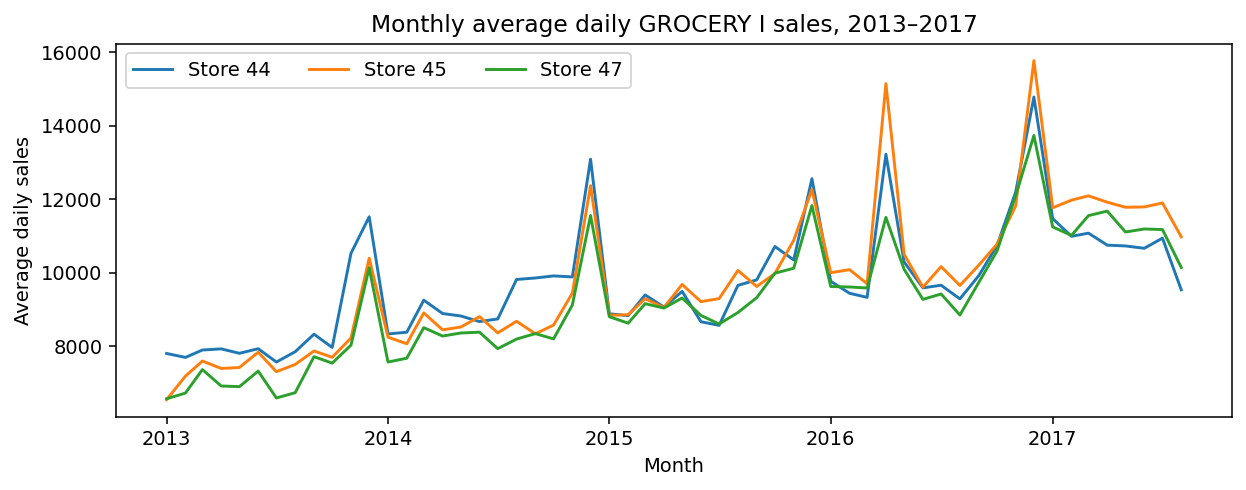

Figure 1 generated successfully.
Saved to: .\figure1_sales_trend.png


In [16]:

# Figure 1: Average daily sales by month and store
# This is the first of four figures used in the capstone analysis.

# ------------------------------------------------------------
# Step 1: Configure the chart appearance
# ------------------------------------------------------------

# Set the default font size for chart labels and titles.
# Set the figure resolution to 140 dots per inch (DPI).
plt.rcParams.update({
    'font.size': 10,
    'figure.dpi': 140
})

# Create a figure and an axis for the line chart.
# The figure measures 9 inches wide and 3.6 inches tall.
fig, ax = plt.subplots(figsize=(9, 3.6))


# ------------------------------------------------------------
# Step 2: Calculate monthly average daily sales by store
# ------------------------------------------------------------

# Group the selected GROCERY I sales observations by store.
# The dataset contains stores 44, 45, and 47.
for st, g in s.groupby('store_nbr'):

    # Set the date column as the DataFrame index.
    # This allows the sales records to be grouped by month.
    #
    # resample('MS') groups observations by calendar month,
    # with each monthly period labeled by its starting date.
    #
    # mean() calculates the average DAILY sales recorded
    # during each month, rather than total monthly sales.
    t = (
        g.set_index('date')['sales']
         .resample('MS')
         .mean()
    )

    # Plot the monthly average daily sales for the current store.
    # t.index contains the monthly dates on the horizontal axis.
    # t.values contains the corresponding average daily sales.
    # Each store is displayed as a separate line.
    # lw=1.5 specifies the line width.
    ax.plot(
        t.index,
        t.values,
        label=f'Store {st}',
        lw=1.5
    )


# ------------------------------------------------------------
# Step 3: Add chart title, labels, and legend
# ------------------------------------------------------------

# Add a descriptive title and label both axes.
ax.set(
    title='Monthly average daily GROCERY I sales, 2013–2017',
    ylabel='Average daily sales',
    xlabel='Month'
)

# Display a legend identifying the three stores.
# ncol=3 arranges the legend entries in three columns.
ax.legend(ncol=3)


# ------------------------------------------------------------
# Step 4: Adjust the chart layout
# ------------------------------------------------------------

# Automatically adjust spacing to reduce overlapping
# labels and prevent chart elements from being cut off.
fig.tight_layout()


# ------------------------------------------------------------
# Step 5: Save the chart as a PNG image
# ------------------------------------------------------------

# Save the figure in the working directory.
# The saved image can be inserted into the capstone white paper.
fig.savefig(
    os.path.join(OUT, 'figure1_sales_trend.png')
)


# ------------------------------------------------------------
# Step 6: Display the chart in the Jupyter notebook
# ------------------------------------------------------------

# Display the completed chart directly below this code cell.
plt.show()


# ------------------------------------------------------------
# Step 7: Confirm that the figure was saved
# ------------------------------------------------------------

# Display the output filename for documentation.
print("Figure 1 generated successfully.")
print(
    "Saved to:",
    os.path.join(OUT, 'figure1_sales_trend.png')
)


**Findings.** All three stores show a rising historical level and recurring year-end peaks. These patterns motivate the use of calendar features, but historical patterns may not generalize to future years.

### Figure 2 — Weekday sales patterns

Compare average recorded sales by weekday to understand the calendar pattern relevant to Research Question 2.

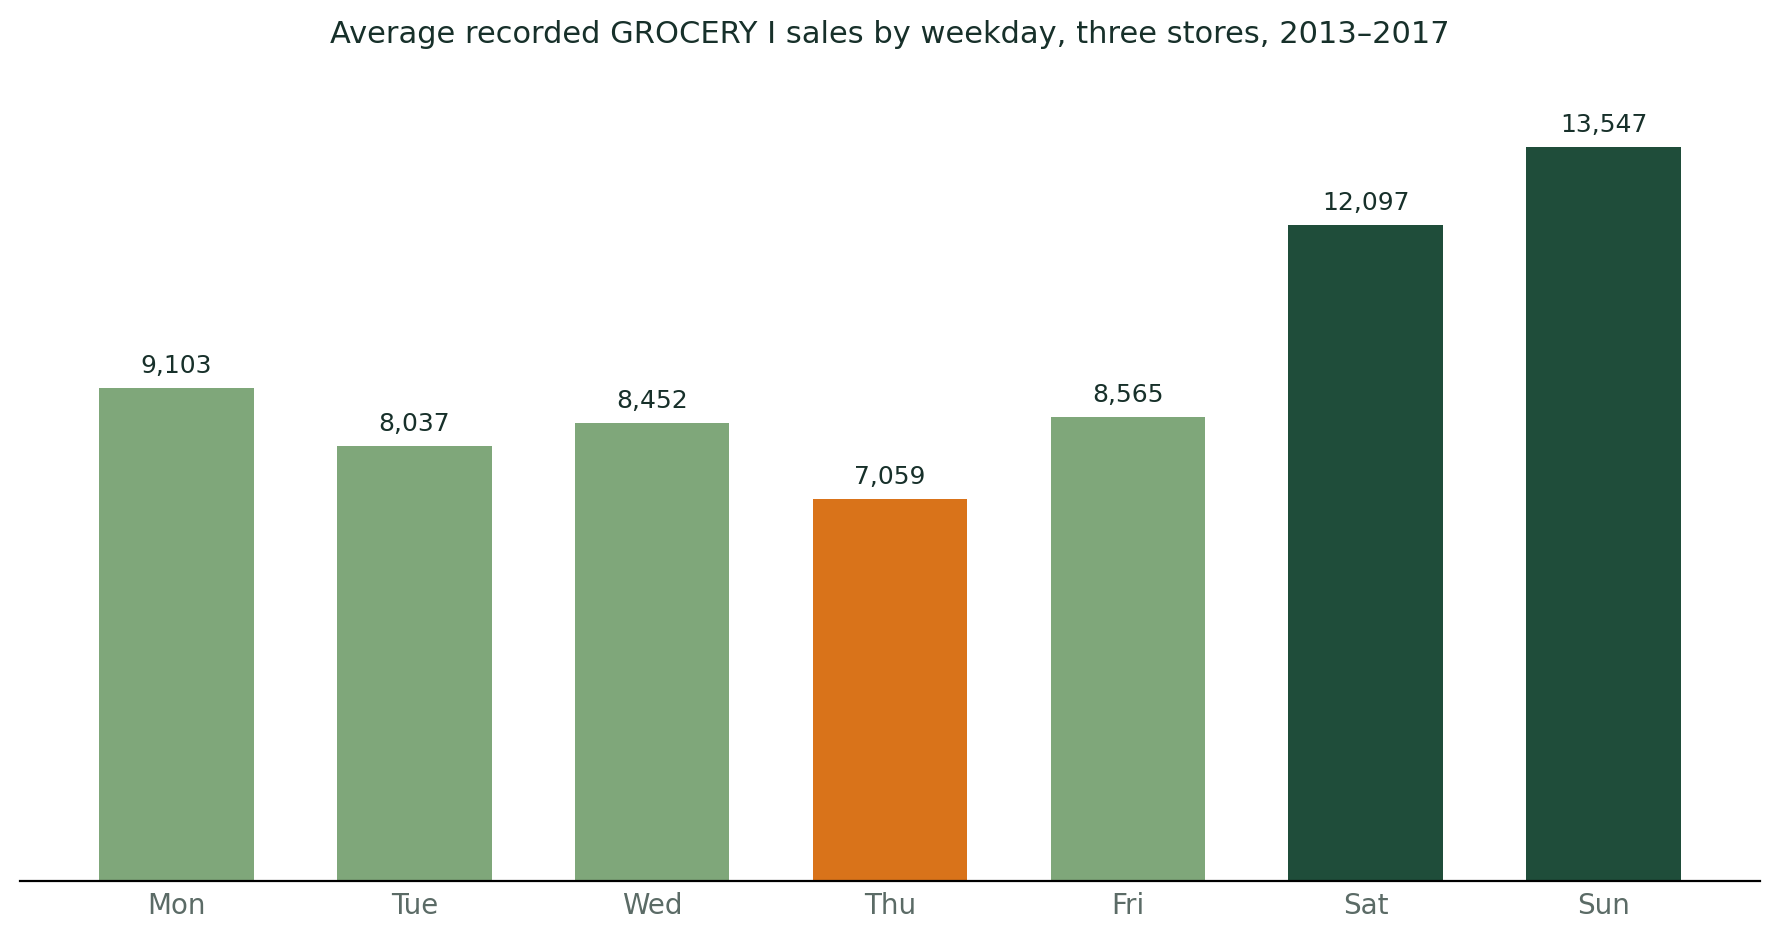

Average GROCERY I sales by weekday:
weekday
Monday        9102.94
Tuesday       8036.91
Wednesday     8451.70
Thursday      7058.60
Friday        8564.85
Saturday     12096.74
Sunday       13547.31

Figure 2 generated successfully.
Saved to: .\figure2_weekday.png


In [17]:
# Figure 2: Weekday averages for the selected stores

# ------------------------------------------------------------
# Step 1: Calculate average sales by day of the week
# ------------------------------------------------------------

# Create a temporary weekday column using the date field.
# dt.day_name() converts each date into its weekday name.
# assign() creates the column without modifying the original
# sales DataFrame (s).
weekday_sales = s.assign(
    weekday=s['date'].dt.day_name()
)

# Calculate the mean recorded GROCERY I sales for each day
# across the three selected stores (44, 45, and 47).
weekday_avg = weekday_sales.groupby('weekday')['sales'].mean()

# Arrange the weekdays in chronological order.
# By default, groupby() sorts weekday names alphabetically.
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]
weekday_avg = weekday_avg.reindex(weekday_order)


# ------------------------------------------------------------
# Step 2: Define the presentation color palette
# ------------------------------------------------------------

# These colors match the capstone presentation (slide 6):
# sage for weekdays, orange to highlight the slowest day (Thursday),
# and forest green for the high-demand weekend days.
SAGE = '#7FA77A'
ORANGE = '#D9731A'
FOREST = '#1F4D3A'
INK = '#17302A'
MUTED = '#5B6B66'

weekday_colors = [
    SAGE, SAGE, SAGE, ORANGE, SAGE, FOREST, FOREST
]


# ------------------------------------------------------------
# Step 3: Generate the weekday sales bar chart
# ------------------------------------------------------------

# Create the figure with the same proportions as the slide chart.
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=200)

# Plot one vertical bar per weekday using abbreviated day names.
short_days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
bars = ax.bar(short_days, weekday_avg.values, color=weekday_colors, width=0.65)

# Label each bar with its average sales value (for example, 13,547).
for bar, value in zip(bars, weekday_avg.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + weekday_avg.max() * 0.015,
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        color=INK
    )


# ------------------------------------------------------------
# Step 4: Add the title and simplify the chart frame
# ------------------------------------------------------------

ax.set_title(
    'Average recorded GROCERY I sales by weekday, three stores, 2013–2017',
    fontsize=11,
    color=INK
)

# The value labels replace the vertical axis, so hide it
# and remove unnecessary borders for a cleaner presentation.
ax.yaxis.set_visible(False)
for edge in ('top', 'right', 'left'):
    ax.spines[edge].set_visible(False)
ax.tick_params(axis='x', colors=MUTED, labelsize=10, length=0)
ax.set_ylim(0, weekday_avg.max() * 1.12)

fig.tight_layout()


# ------------------------------------------------------------
# Step 5: Save and display Figure 2
# ------------------------------------------------------------

# Save the figure in the working directory for use in the
# capstone white paper and presentation.
fig.savefig(
    os.path.join(OUT, 'figure2_weekday.png'),
    bbox_inches='tight'
)
plt.show()

# Display the underlying average sales values used in the chart.
print("Average GROCERY I sales by weekday:")
print(weekday_avg.round(2).to_string())

print("\nFigure 2 generated successfully.")
print("Saved to:", os.path.join(OUT, 'figure2_weekday.png'))

In [18]:

# Report exact weekday means to support the chart interpretation

# ------------------------------------------------------------
# Step 1: Define the weekday display order
# ------------------------------------------------------------

# Arrange weekdays in calendar order, beginning with Monday.
# This ensures the reported results match the order of the
# weekday bars displayed in Figure 2.
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]


# ------------------------------------------------------------
# Step 2: Calculate average daily sales for each weekday
# ------------------------------------------------------------

# Create a temporary weekday column from the transaction date.
# dt.day_name() converts each date to its corresponding weekday.
#
# Group the observations by weekday and calculate the mean
# recorded GROCERY I sales across stores 44, 45, and 47.
#
# reindex() arranges the results from Monday through Sunday
# rather than displaying the weekday names alphabetically.
weekday_means = (
    s.assign(
        weekday=s["date"].dt.day_name()
    )
    .groupby("weekday")["sales"]
    .mean()
    .reindex(weekday_order)
)


# ------------------------------------------------------------
# Step 3: Display the weekday sales averages
# ------------------------------------------------------------

# Round the average sales values to one decimal place
# to make the results easier to read.
#
# to_string() displays all seven weekdays in a readable
# text format without truncating the output.
print(weekday_means.round(1).to_string())


weekday
Monday        9102.9
Tuesday       8036.9
Wednesday     8451.7
Thursday      7058.6
Friday        8564.8
Saturday     12096.7
Sunday       13547.3


**Findings.** Recorded sales are highest on **Sunday and Saturday** and lowest on **Thursday** in this selected sample. Weekday differences are descriptive and should not be interpreted as causal effects.

### Figure 3 — Compare final holdout forecast error

This figure emphasizes **mean absolute error (MAE)** because a retail planner can interpret the average number of recorded sales units missed. It also displays WAPE and improvement relative to the seasonal naïve baseline.

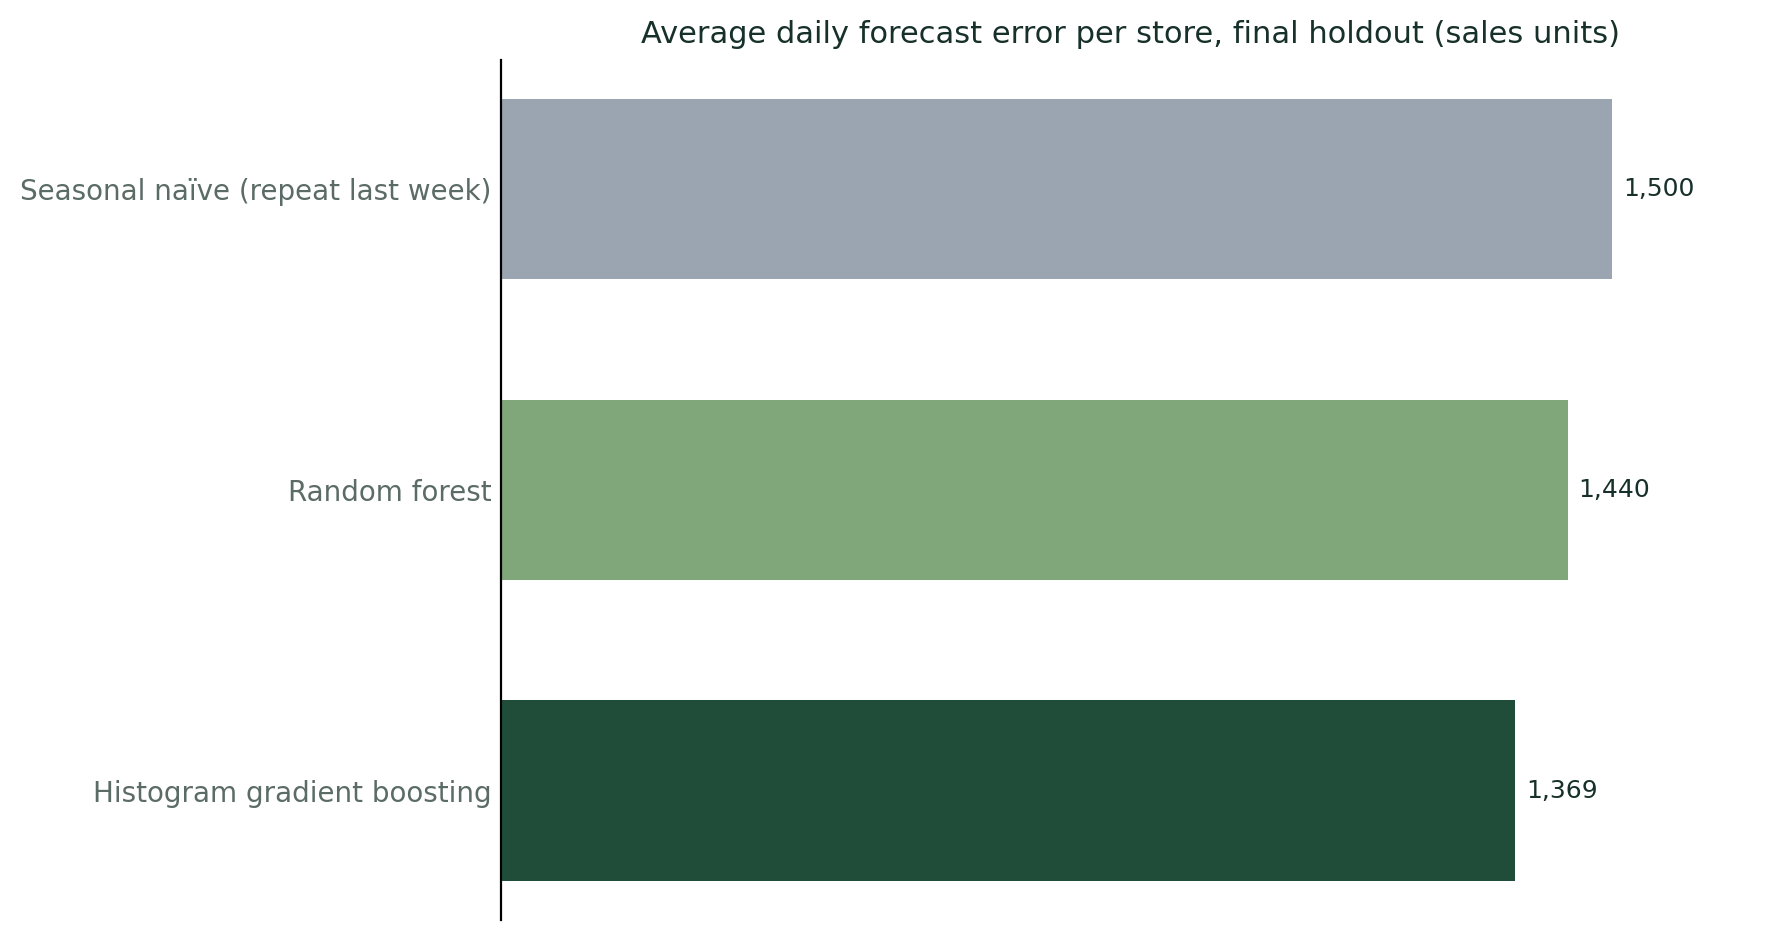

Figure 3 improvement calculated from unrounded MAE: {'Random forest': np.float64(4.01), 'Histogram gradient boosting': np.float64(8.75)}
Final holdout WAPE (%): {'Seasonal naïve': 14.6, 'Random forest': 14.0, 'Histogram gradient boosting': 13.3}


In [19]:
# Figure 3: Compare final holdout forecast errors across three forecasting methods.
# This visualization uses the original, unrounded model results so the
# reported MAE values and percentage improvements are calculated accurately.

# ------------------------------------------------------------
# Step 1: Select the final holdout results
# ------------------------------------------------------------

# Define the order in which the forecasting methods will appear.
order = [
    'Seasonal naïve',
    'Random forest',
    'Histogram gradient boosting'
]

# Select the final holdout evaluation results (forecast origin: July 30, 2017).
final = res[res.origin == '2017-07-30'].set_index('model').loc[order]

# Descriptive labels; the seasonal naïve model repeats last week's sales.
methods = [
    'Seasonal naïve (repeat last week)',
    'Random forest',
    'Histogram gradient boosting'
]

# Extract Mean Absolute Error (MAE) for each method.
mae = final.MAE.to_numpy()


# ------------------------------------------------------------
# Step 2: Define the presentation color palette
# ------------------------------------------------------------

# These colors match the capstone presentation (slide 9):
# gray for the baseline, sage for random forest, and
# forest green for the best model, gradient boosting.
GRAY = '#9AA5B1'
SAGE = '#7FA77A'
FOREST = '#1F4D3A'
INK = '#17302A'
MUTED = '#5B6B66'
colors = [GRAY, SAGE, FOREST]


# ------------------------------------------------------------
# Step 3: Create the horizontal bar chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=200)

# Plot MAE values as horizontal bars. Lower MAE means better accuracy.
bars = ax.barh(methods, mae, color=colors, height=0.6)

# Display the seasonal naïve benchmark at the top of the chart.
ax.invert_yaxis()

# Label each bar with its MAE value (for example, 1,369).
for bar, m in zip(bars, mae):
    ax.text(
        m + max(mae) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{m:,.0f}',
        va='center',
        fontsize=9,
        color=INK
    )


# ------------------------------------------------------------
# Step 4: Add the title and simplify the chart frame
# ------------------------------------------------------------

ax.set_title(
    'Average daily forecast error per store, final holdout (sales units)',
    fontsize=11,
    color=INK
)

# The value labels replace the horizontal axis, so hide it
# and remove unnecessary borders for a cleaner presentation.
ax.xaxis.set_visible(False)
for edge in ('top', 'right', 'bottom'):
    ax.spines[edge].set_visible(False)
ax.tick_params(axis='y', colors=MUTED, labelsize=10, length=0)
ax.set_xlim(0, 1700)

fig.tight_layout()


# ------------------------------------------------------------
# Step 5: Save and display Figure 3
# ------------------------------------------------------------

# Save the figure in the working directory for use in the
# capstone white paper and presentation.
fig.savefig(
    os.path.join(OUT, 'figure3_holdout_comparison.png'),
    bbox_inches='tight'
)
plt.show()


# ------------------------------------------------------------
# Step 6: Report the exact improvements over the baseline
# ------------------------------------------------------------

# Calculate each model's MAE reduction relative to the seasonal naïve
# baseline, using unrounded values. These figures support the 8.8%
# improvement reported in the white paper and presentation.
base = mae[0]
print(
    'Figure 3 improvement calculated from unrounded MAE:',
    {
        order[i]: round((base - mae[i]) / base * 100, 2)
        for i in range(1, 3)
    }
)
print('Final holdout WAPE (%):', (final.WAPE * 100).round(1).to_dict())

**Findings.** The holdout MAE is approximately **1,500** units for seasonal naïve, **1,440** for random forest, and **1,369** for histogram gradient boosting. Using unrounded values, boosting improves MAE by approximately **8.8%** versus the baseline. Rounding the MAEs to whole numbers first can yield 8.7%; the chart calculates from the original model outputs.

### Figure 4 — Forecasts versus actual sales

Visualize all three forecasting methods alongside observed sales for each store during the final 16-day holdout.

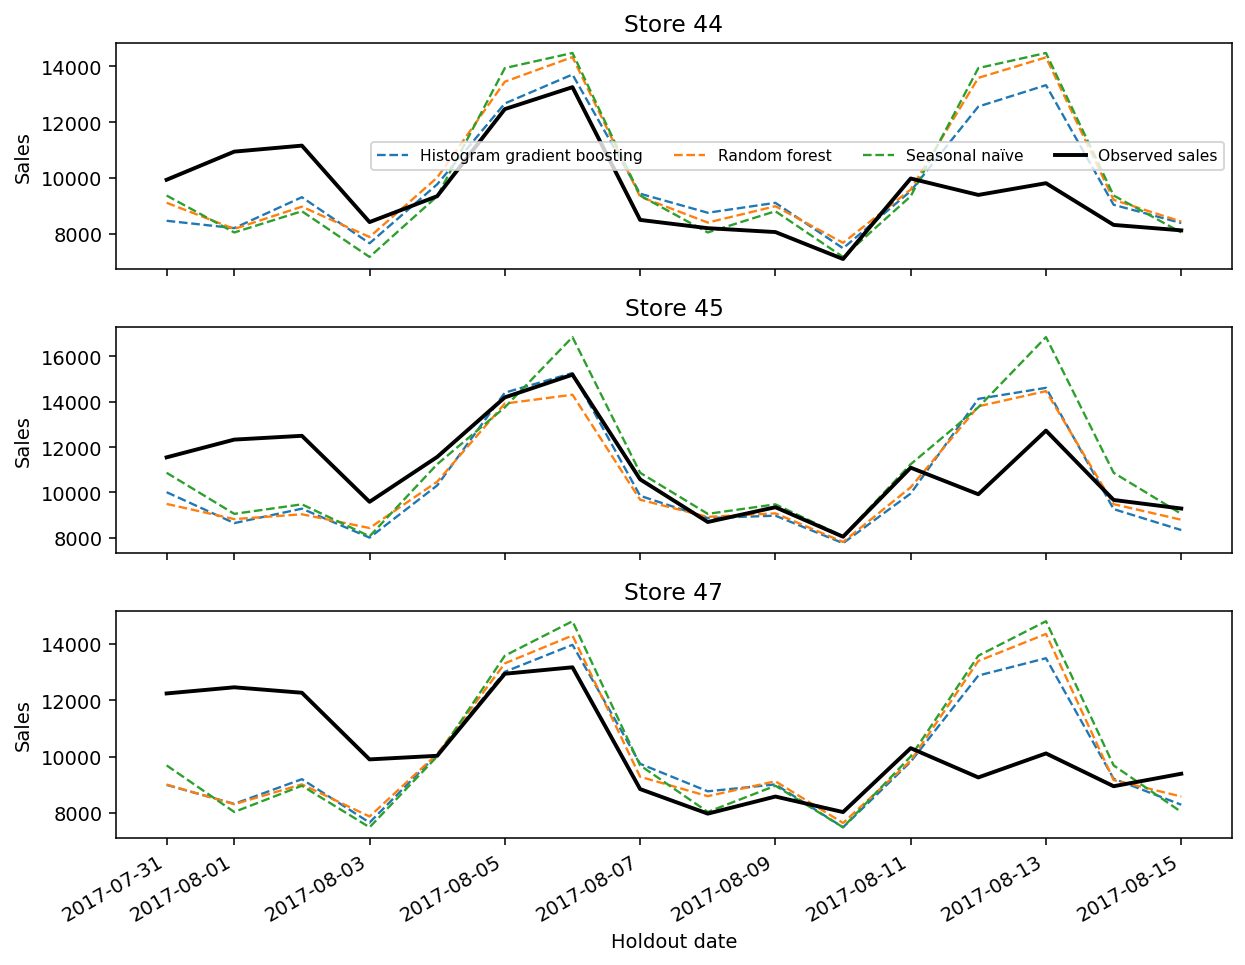

Figure 4 generated successfully.
Stores represented: 3
Holdout forecast dates: 16
Saved to: .\figure4_forecasts.png


In [20]:

# Figure 4: Store-level daily predictions versus actual sales

# ------------------------------------------------------------
# Step 1: Create the figure and three store-level charts
# ------------------------------------------------------------

# Create three vertically stacked subplots.
# Each subplot represents one of the selected stores:
# Store 44, Store 45, and Store 47.
#
# figsize=(9, 7) sets the overall figure dimensions.
# sharex=True ensures all three charts use the same date axis.
fig, axes = plt.subplots(
    3,
    1,
    figsize=(9, 7),
    sharex=True
)


# ------------------------------------------------------------
# Step 2: Select the final holdout predictions
# ------------------------------------------------------------

# Filter the prediction dataset to the final holdout origin.
# The forecast origin is July 30, 2017.
# The corresponding 16-day holdout covers July 31–August 15.
holdout_predictions = preds[
    preds['origin'] == pd.Timestamp('2017-07-30')
]


# ------------------------------------------------------------
# Step 3: Plot predictions and actual sales for each store
# ------------------------------------------------------------

# Group the holdout predictions by store number.
# zip() pairs each store's observations with one subplot.
for ax, (st, g) in zip(
    axes,
    holdout_predictions.groupby('store_nbr')
):

    # Group the current store's predictions by forecasting method.
    # The three methods are:
    # 1. Seasonal naïve
    # 2. Random forest
    # 3. Histogram gradient boosting
    for model, p in g.groupby('model'):

        # Plot the predicted daily sales for the current model.
        # target_date identifies the forecast date.
        # prediction contains the predicted sales values.
        # Dashed lines distinguish forecasts from actual sales.
        # lw=1.2 specifies the forecast line width.
        ax.plot(
            p['target_date'],
            p['prediction'],
            label=model,
            ls='--',
            lw=1.2
        )

    # --------------------------------------------------------
    # Step 4: Plot the actual recorded sales
    # --------------------------------------------------------

    # Select one set of actual sales observations.
    # Actual sales are repeated for each forecasting method,
    # so selecting the seasonal naïve rows avoids plotting
    # the same observed values multiple times.
    actual = g[
        g['model'] == 'Seasonal naïve'
    ]

    # Plot the observed sales as a solid black line.
    # A thicker line makes actual sales easier to distinguish
    # from the three dashed forecast lines.
    ax.plot(
        actual['target_date'],
        actual['y'],
        label='Observed sales',
        lw=2,
        c='black'
    )

    # Add the store number as the subplot title.
    # Label the vertical axis with the sales measurement.
    ax.set(
        title=f'Store {st}',
        ylabel='Sales'
    )


# ------------------------------------------------------------
# Step 5: Add the legend and horizontal axis label
# ------------------------------------------------------------

# Display the legend on the first subplot.
# The legend identifies all three forecasting methods
# and the observed sales series.
# ncol=4 arranges the four entries in one row.
axes[0].legend(
    ncol=4,
    fontsize=8
)

# Label the shared horizontal axis on the bottom subplot.
axes[-1].set_xlabel('Holdout date')


# ------------------------------------------------------------
# Step 6: Format the chart layout
# ------------------------------------------------------------

# Automatically format the date labels to improve readability.
fig.autofmt_xdate()

# Adjust spacing between subplots, titles, and labels.
fig.tight_layout()


# ------------------------------------------------------------
# Step 7: Save Figure 4
# ------------------------------------------------------------

# Save the store-level forecast comparison as a PNG file.
# The figure will be saved in the working directory
# for inclusion in the capstone white paper and presentation.
fig.savefig(
    os.path.join(OUT, 'figure4_forecasts.png')
)


# ------------------------------------------------------------
# Step 8: Display Figure 4
# ------------------------------------------------------------

# Display the three store-level forecast comparison charts.
plt.show()


# ------------------------------------------------------------
# Step 9: Confirm figure generation
# ------------------------------------------------------------

# Display the number of stores and forecast dates represented.
print("Figure 4 generated successfully.")
print(
    "Stores represented:",
    holdout_predictions['store_nbr'].nunique()
)
print(
    "Holdout forecast dates:",
    holdout_predictions['target_date'].nunique()
)

# Display the saved figure location.
print(
    "Saved to:",
    os.path.join(OUT, 'figure4_forecasts.png')
)


**Findings.** Even the best overall method can miss individual peaks or troughs. A lower average error does not mean every forecast is accurate. The figures support using forecasts as **decision support**, not automatic purchasing instructions.

## Summary of results and reproducibility

Export the metrics, prediction tables, and summary information so a reader can reproduce and independently review the results.

In [21]:

# Save the summary and descriptive promotion statistics

# Research Question 2 (RQ2):
# Examine the relationship between promotional activity and sales.
#
# This analysis is descriptive only.
# It does not establish that promotions cause higher sales.
# Promotional activity is not included as a forecasting predictor
# because future promotional schedules were not verified as
# available at the time each forecast was generated.


# ------------------------------------------------------------
# Step 1: Calculate descriptive promotion statistics
# ------------------------------------------------------------

# Identify whether each observation had promotional activity.
# onpromotion > 0 indicates at least one promoted item.
# onpromotion == 0 indicates no recorded promoted items.
#
# Group the selected GROCERY I sales observations by
# promotional status across stores 44, 45, and 47.
#
# Calculate three descriptive statistics:
# count  - Number of daily store-level observations.
# mean   - Average recorded sales.
# median - Middle sales value when observations are ordered.
prom = (
    s.groupby(s['onpromotion'].gt(0))['sales']
    .agg(['count', 'mean', 'median'])
)

# Display the descriptive promotion statistics.
# False represents observations without recorded promotions.
# True represents observations with promotional activity.
print("Descriptive promotional activity statistics:")
print(prom)


# ------------------------------------------------------------
# Step 2: Prepare the project summary information
# ------------------------------------------------------------

# Calculate the total number of observations in the
# selected GROCERY I sales dataset.
subset_rows = len(s)

# Count observations where recorded sales equal zero.
# These observations are retained in the analysis.
zero_sales = int((s['sales'] == 0).sum())


# ------------------------------------------------------------
# Step 3: Calculate average validation performance
# ------------------------------------------------------------

# Exclude the final holdout origin from validation results.
# The first three chronological windows are used to
# summarize historical validation performance.
validation_results = res[
    res['origin'] != '2017-07-30'
]

# Group validation results by forecasting method.
# Calculate average RMSLE, MAE, and WAPE across the
# three validation windows.
#
# Round the metrics to five decimal places.
# Convert the results to a nested dictionary for JSON storage.
validation_summary = (
    validation_results
    .groupby('model')[['RMSLE', 'MAE', 'WAPE']]
    .mean()
    .round(5)
    .to_dict('index')
)


# ------------------------------------------------------------
# Step 4: Prepare final holdout performance
# ------------------------------------------------------------

# Select only the final holdout evaluation period.
# The forecast origin is July 30, 2017.
# The holdout covers July 31 through August 15, 2017.
holdout_results = res[
    res['origin'] == '2017-07-30'
]

# Use the model name as the dictionary key.
# Retain RMSLE, MAE, and WAPE for each forecasting method.
#
# Round the results to five decimal places and convert
# them into a nested dictionary for JSON storage.
holdout_summary = (
    holdout_results
    .set_index('model')[['RMSLE', 'MAE', 'WAPE']]
    .round(5)
    .to_dict('index')
)


# ------------------------------------------------------------
# Step 5: Create the project summary dictionary
# ------------------------------------------------------------

# Combine the dataset characteristics, descriptive promotion
# statistics, validation results, and final holdout results
# into one structured summary.
#
# reset_index() converts promotional status into a column.
# to_dict('records') creates a list of promotion records.
summary = {
    'subset_rows': subset_rows,
    'zeros': zero_sales,
    'promo_stats': prom.reset_index().to_dict('records'),
    'validation': validation_summary,
    'holdout': holdout_summary
}


# ------------------------------------------------------------
# Step 6: Save the summary as a JSON file
# ------------------------------------------------------------

# Define the location and filename for the summary.
# The file is saved directly in the current working directory.
summary_path = os.path.join(
    ROOT,
    'week11_summary.json'
)

# Open the output file in write mode.
# json.dump() saves the summary dictionary as JSON.
# indent=2 formats the file for readability.
with open(summary_path, 'w') as h:
    json.dump(summary, h, indent=2)


# ------------------------------------------------------------
# Step 7: Display the project summary
# ------------------------------------------------------------

# Display the number of selected observations and zero-sales days.
print("\nDataset summary:")
print("Total selected observations:", subset_rows)
print("Zero-sales observations:", zero_sales)

# Display average validation performance for each model.
print("\nAverage validation performance:")
print(
    pd.DataFrame.from_dict(
        validation_summary,
        orient='index'
    ).to_string()
)

# Display the final holdout evaluation metrics.
print("\nFinal holdout performance:")
print(
    pd.DataFrame.from_dict(
        holdout_summary,
        orient='index'
    ).to_string()
)

# Confirm that the JSON summary file has been saved.
print("\nProject summary saved successfully.")
print("Saved to:", summary_path)


Descriptive promotional activity statistics:
             count          mean  median
onpromotion                             
False         1648   8015.115291  7115.5
True          3404  10294.190605  9342.0

Dataset summary:
Total selected observations: 5052
Zero-sales observations: 15

Average validation performance:
                               RMSLE         MAE     WAPE
Histogram gradient boosting  0.11189   987.28941  0.08977
Random forest                0.11438  1013.33383  0.09221
Seasonal naïve               0.13770  1199.68750  0.10957

Final holdout performance:
                               RMSLE         MAE     WAPE
Seasonal naïve               0.19044  1500.35417  0.14590
Random forest                0.18304  1440.11728  0.14004
Histogram gradient boosting  0.17550  1369.05283  0.13313

Project summary saved successfully.
Saved to: .\week11_summary.json


## Conclusions, limitations, and ethical considerations

**RQ1:** A 16-day forecast is feasible for the selected store–family series, with measurable prediction error.

**RQ2:** Calendar patterns are pronounced: Sunday averaged about 13,547 recorded sales and Saturday 12,097, versus 7,059 on Thursday. The raw promotion comparison (10,294 versus 8,015) is not reliable because promotion counts begin on June 25, 2014, and 1,617 of the 1,648 no-promotion days precede that date. The three stores share a city and type, limiting store-characteristic comparisons.

**RQ3:** Both machine-learning models outperform the weekly seasonal naïve baseline on the final holdout. Histogram gradient boosting has the lowest measured error in that period.

**Limitations.** The data are historical (2013–2017), only one product family and three stores are included, and recorded sales may understate true demand when stockouts occur. Inventory levels, lead times, and replenishment costs were unavailable, so this project does not measure inventory savings.

**Ethical assessment.** Using forecasts to automate orders could cause stock shortages or excess stock. The recommended mitigation is a monitored pilot with planner review, documented overrides, and ongoing error tracking. The Kaggle dataset is aggregated at the store/family level, and the analysis does not use customer-level personal data.

**Recommendations.** Pilot 16-day forecasts alongside the existing seasonal rule, monitor errors by store and horizon, and expand to other stores and families only after repeated backtesting.

**Reproducibility outputs:** The notebook saves all generated files directly in the working directory, including week11_model_metrics.csv, week11_forecast_predictions.csv, week11_summary.json, and four PNG figures (figure1_sales_trend.png, figure2_weekday.png, figure3_holdout_comparison.png, and figure4_forecasts.png).

**References:** Kaggle, *Store Sales – Time Series Forecasting*; Hyndman & Athanasopoulos (2021), *Forecasting: Principles and Practice* (3rd ed.).
